# 03.6 — Inferência Clássica: Threshold Analysis + Odds Ratios
**Depende de:** 03.3 executado antes (artefatos em out/artifacts/)
**Salva em:** out/03.6_inferencia/

In [1]:
from __future__ import annotations

import json
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)

# ── Idioma / Language ─────────────────────────────────────────────────────────
LANG = "pt"  # "pt" | "en"  ← única linha a alterar para mudar idioma

_T = {
    "pt": {
        "thresh_sens_lbl":    "Sensibilidade",
        "thresh_spec_lbl":    "Especificidade",
        "thresh_ppv_lbl":     "PPV (Precisão)",
        "thresh_f1_lbl":      "F1-Score",
        "thresh_fixo_lbl":    "Threshold=0.30",
        "thresh_youden_fmt":  "Threshold Youden={thr:.3f}",
        "thresh_xlabel":      "Threshold de Decisão",
        "thresh_ylabel":      "Valor da Métrica",
        "thresh_title_fmt":   "Análise de Threshold — {nome} | Retorno 30d",
        "forest_xlabel":      "Odds Ratio (IC95%)",
        "forest_title":       "Forest Plot — OR Significativos (p<0.05)\nRetorno 30d",
    },
    "en": {
        "thresh_sens_lbl":    "Sensitivity",
        "thresh_spec_lbl":    "Specificity",
        "thresh_ppv_lbl":     "PPV (Precision)",
        "thresh_f1_lbl":      "F1-Score",
        "thresh_fixo_lbl":    "Threshold=0.30",
        "thresh_youden_fmt":  "Youden Threshold={thr:.3f}",
        "thresh_xlabel":      "Decision Threshold",
        "thresh_ylabel":      "Metric Value",
        "thresh_title_fmt":   "Threshold Analysis — {nome} | 30-day Return",
        "forest_xlabel":      "Odds Ratio (95% CI)",
        "forest_title":       "Forest Plot — Significant ORs (p<0.05)\n30-day Return",
    },
}
T = _T[LANG]

# Paths
ROOT     = Path("..").resolve()
DATA_DIR = ROOT / "data"
OUT_DIR  = ROOT / "out" / "03.6_inferencia"
PLOT_DIR = OUT_DIR / "plots"
ART_DIR  = ROOT / "out" / "artifacts"   # shared state between sub-files

OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
ART_DIR.mkdir(parents=True, exist_ok=True)

## Carregar Artefatos

In [2]:
with open(ART_DIR / "splits.pkl", "rb") as f:
    _splits = pickle.load(f)

df_train  = _splits["df_train"]
df_valid  = _splits["df_valid"]
df_test   = _splits["df_test"]
y_train   = _splits["y_train"]
y_valid   = _splits["y_valid"]
y_test    = _splits["y_test"]
X_train_t = _splits["X_train_t"]
X_valid_t = _splits["X_valid_t"]
X_test_t  = _splits["X_test_t"]
X_train   = _splits["X_train"]
X_valid   = _splits["X_valid"]
X_test    = _splits["X_test"]

with open(ART_DIR / "features.json", "r", encoding="utf-8") as f:
    _feat = json.load(f)
FEATURES         = _feat["FEATURES"]
TARGET_PRINCIPAL = _feat["TARGET_PRINCIPAL"]
THRESHOLD        = _feat["THRESHOLD"]
TARGETS          = _feat["TARGETS"]

# _Dummy precisa existir neste escopo antes de unpickle
class _Dummy:
    def __init__(self, prev=0.5):
        self.prev = prev
    def predict_proba(self, X):
        n = len(X) if hasattr(X, "__len__") else X.shape[0]
        return np.column_stack([1 - self.prev * np.ones(n),
                                       self.prev * np.ones(n)])

with open(ART_DIR / "modelos_fit.pkl", "rb") as f:
    modelos_fit = pickle.load(f)

with open(ART_DIR / "probs_teste.pkl", "rb") as f:
    probs_teste = pickle.load(f)

with open(ART_DIR / "thresholds_opt.json", "r", encoding="utf-8") as f:
    threshold_youden_por_modelo = json.load(f)

with open(ART_DIR / "preprocessor.pkl", "rb") as f:
    _preproc_d = pickle.load(f)
preproc = _preproc_d["preproc"]

CORES = ["steelblue", "darkorange", "seagreen", "firebrick",
         "mediumpurple", "saddlebrown", "deeppink", "teal"]

print(f"Modelos carregados: {list(modelos_fit.keys())}")

# ── Flags e helpers ────────────────────────────────────────────────────────
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    from lightgbm import LGBMClassifier
    HAS_LGB = True
except ImportError:
    HAS_LGB = False

try:
    from catboost import CatBoostClassifier
    HAS_CAT = True
except ImportError:
    HAS_CAT = False


def _predict_proba(nome, clf, X_raw, X_transformed):
    if nome == "M5_CAT" and HAS_CAT:
        return clf.predict_proba(X_raw)[:, 1]
    try:
        return clf.predict_proba(X_transformed)[:, 1]
    except Exception:
        return clf.predict_proba(X_raw)[:, 1]

## 16. Threshold Analysis

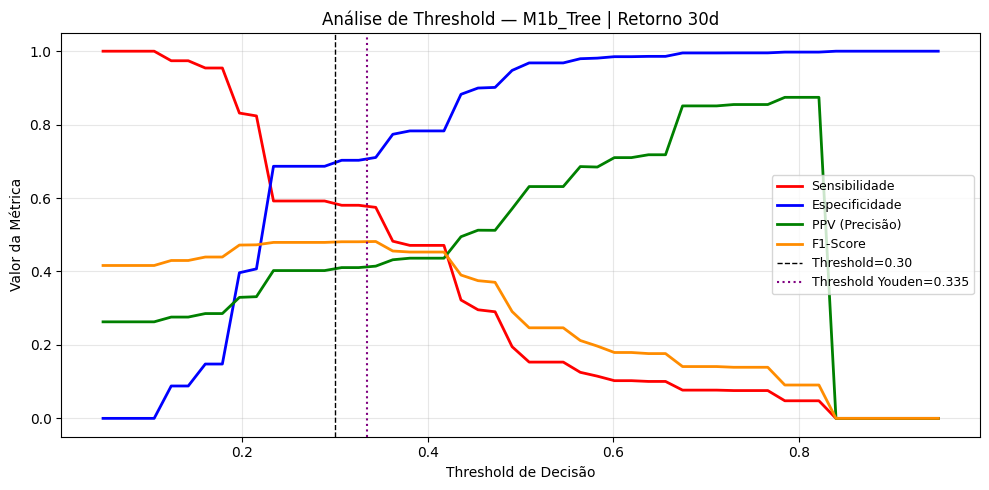

In [5]:
nome_plot = next(n for n in ["M1b_Tree","M2_RF", "M3_XGB","M4_LGB","M5_CAT"] if n in modelos_fit)
clf_plot  = modelos_fit[nome_plot]
prob_plt  = _predict_proba(nome_plot, clf_plot, X_test, X_test_t)
thresholds_arr = np.linspace(0.05, 0.95, 50)

sens_list, spec_list, ppv_list, f1_list = [], [], [], []
for thr in thresholds_arr:
    y_pred = (prob_plt >= thr).astype(int)
    tp = ((y_test == 1) & (y_pred == 1)).sum()
    tn = ((y_test == 0) & (y_pred == 0)).sum()
    fp = ((y_test == 0) & (y_pred == 1)).sum()
    fn = ((y_test == 1) & (y_pred == 0)).sum()
    sens_list.append(tp / (tp + fn + 1e-9))
    spec_list.append(tn / (tn + fp + 1e-9))
    ppv_list.append(tp / (tp + fp + 1e-9))
    f1_list.append(2 * tp / (2 * tp + fp + fn + 1e-9))

thr_youd_plot = threshold_youden_por_modelo.get(nome_plot, 0.30)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds_arr, sens_list, label=T["thresh_sens_lbl"],  color="red",       lw=2)
ax.plot(thresholds_arr, spec_list, label=T["thresh_spec_lbl"], color="blue",      lw=2)
ax.plot(thresholds_arr, ppv_list,  label=T["thresh_ppv_lbl"], color="green",     lw=2)
ax.plot(thresholds_arr, f1_list,   label=T["thresh_f1_lbl"],       color="darkorange",lw=2)
ax.axvline(0.30,           color="black",  ls="--", lw=1, label=T["thresh_fixo_lbl"])
ax.axvline(thr_youd_plot,  color="purple", ls=":",  lw=1.5,
           label=T["thresh_youden_fmt"].format(thr=thr_youd_plot))
ax.set_xlabel(T["thresh_xlabel"]); ax.set_ylabel(T["thresh_ylabel"])
ax.set_title(T["thresh_title_fmt"].format(nome=nome_plot))
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_DIR / "06_threshold_analysis.png", dpi=150)
plt.show()

# Salvar dados da análise de threshold
thr_df = pd.DataFrame({
    "threshold": thresholds_arr,
    "sensibilidade": sens_list,
    "especificidade": spec_list,
    "ppv": ppv_list,
    "f1": f1_list,
})
thr_df.to_csv(OUT_DIR / "threshold_analysis.csv", index=False)

## 17. Regressão Logística com Odds Ratios

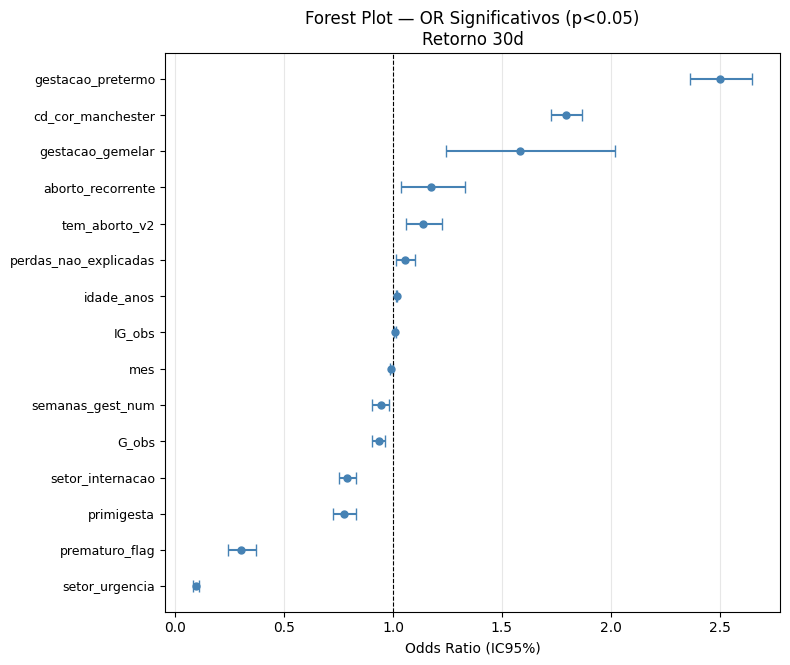

In [4]:
import statsmodels.api as sm

feat_num = [f for f in FEATURES if pd.api.types.is_numeric_dtype(df_train[f])]
X_logit = df_train[feat_num].copy()
X_logit = X_logit.replace([np.inf, -np.inf], np.nan)
X_logit = X_logit.loc[:, X_logit.isna().mean() < 0.9]
for col in X_logit.columns:
    med = X_logit[col].median()
    X_logit[col] = X_logit[col].fillna(med if not np.isnan(med) else 0)

var_cols = X_logit.var()
X_logit = X_logit.loc[:, var_cols > 1e-10]
print(f"  Colunas após filtro variância: {X_logit.shape[1]}")

corr_mat = X_logit.corr().abs()
upper = corr_mat.where(np.triu(np.ones(corr_mat.shape, dtype=bool), k=1))
to_drop = [col for col in upper.columns if any(upper[col] > 0.95)]
if to_drop:
    print(f"  Removidas por correlação >0.95: {to_drop}")
    X_logit = X_logit.drop(columns=to_drop)

X_logit = sm.add_constant(X_logit, has_constant="add")
y_logit = df_train["y_retorno_30d"].astype(int)

fit_logit = None
try:
    fit_logit = sm.Logit(y_logit, X_logit).fit(disp=False, maxiter=200)
except Exception:
    try:
        fit_logit = sm.Logit(y_logit, X_logit).fit_regularized(
            method="l1", alpha=0.1, disp=False, maxiter=200
        )
    except Exception:
        from sklearn.linear_model import LogisticRegression as _LR
        _lr = _LR(penalty="l2", C=1.0, max_iter=1000, solver="lbfgs")
        _lr.fit(X_logit.drop(columns="const", errors="ignore"), y_logit)
        _coefs = np.concatenate([[_lr.intercept_[0]], _lr.coef_[0]])
        _names = ["const"] + [c for c in X_logit.columns if c != "const"]
        fit_logit = None
        print("  Usando sklearn LogisticRegression (statsmodels singular)")

if fit_logit is not None:
    tab_or = pd.DataFrame({
        "variavel": fit_logit.params.index,
        "coef"    : fit_logit.params.values,
        "OR"      : np.exp(fit_logit.params.values),
        "OR_lo95" : np.exp(fit_logit.conf_int()[0].values),
        "OR_hi95" : np.exp(fit_logit.conf_int()[1].values),
        "p_valor" : fit_logit.pvalues.values,
    }).sort_values("p_valor")
else:
    tab_or = pd.DataFrame({
        "variavel": _names,
        "coef"    : _coefs,
        "OR"      : np.exp(_coefs),
        "OR_lo95" : np.nan,
        "OR_hi95" : np.nan,
        "p_valor" : np.nan,
    }).sort_values("OR", ascending=False)
    print("  IC e p-valores indisponíveis (fallback sklearn)")

tab_or = tab_or[tab_or["variavel"] != "const"]
print("\nOdds Ratios — Regressão Logística (features numéricas):")
if fit_logit is not None:
    print(tab_or[tab_or["p_valor"] < 0.05].head(15).to_string(index=False))
else:
    print(tab_or.head(15).to_string(index=False))
tab_or.to_csv(OUT_DIR / "odds_ratios_logit.csv", index=False)

if fit_logit is not None:
    sig = tab_or[tab_or["p_valor"] < 0.05].head(15).sort_values("OR")
else:
    sig = tab_or.iloc[:15].sort_values("OR")

if len(sig) > 0:
    fig, ax = plt.subplots(figsize=(8, max(4, len(sig) * 0.45)))
    y_pos = range(len(sig))
    if fit_logit is not None:
        ax.errorbar(
            sig["OR"], y_pos,
            xerr=[sig["OR"] - sig["OR_lo95"], sig["OR_hi95"] - sig["OR"]],
            fmt="o", color="steelblue", capsize=4, markersize=5,
        )
    else:
        ax.scatter(sig["OR"], list(y_pos), color="steelblue", s=30, zorder=3)
    ax.axvline(1.0, color="black", ls="--", lw=0.8)
    ax.set_yticks(list(y_pos)); ax.set_yticklabels(sig["variavel"], fontsize=9)
    ax.set_xlabel(T["forest_xlabel"])
    ax.set_title(T["forest_title"])
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "07_forest_plot_or.png", dpi=150)
    plt.show()

print(f"\n[03.6] Concluído. Outputs: {OUT_DIR}")